In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

In [2]:
bt = pd.read_csv(OUT / "backtest_summary.csv")
folds = pd.read_csv(OUT / "backtest_by_fold.csv")
ci = pd.read_csv(OUT / "bootstrap_gain.csv")
seg = pd.read_csv(OUT / "segments.csv")
choice = pd.read_csv(OUT / "feature_choice.csv")
sel = json.loads((OUT / "selected_config.json").read_text())
val = json.loads((OUT / "validation_summary.json").read_text())
ext = json.loads((OUT / "external_status.json").read_text())
eda_m = pd.read_csv(OUT / "eda_ratio_by_month.csv")
eda_e = pd.read_csv(OUT / "eda_events.csv")
by_month = pd.read_csv(OUT / "validation_by_month.csv")
pr = pd.read_parquet(OUT / "price_ratios.parquet")
S = sel["name"]
row = lambda m: bt[bt.method == m].iloc[0]
jas, best = row("Jasper real price"), row(S)
raise_all = row("base price x best constant")
g = ci[(ci.method == "selected: " + S) & (ci.demand == "moderate")].iloc[0]
NICE = {"hybrid_constant": "Hybrid, constant multiplier", "hybrid_events": "Hybrid + economic calendar",
        "hybrid_fear_greed": "Hybrid + Fear & Greed", "hybrid_events_fear_greed": "Hybrid + calendar + Fear & Greed",
        "hybrid_size_capped": "Hybrid + order size (capped)", "hybrid_market": "Hybrid + market inputs",
        "hybrid_all_glm": "Hybrid + all inputs (GLM)", "hybrid_all_gbm": "Hybrid + all inputs (boosting)",
        "hybrid_events_const_reference": "Hybrid + calendar, simple reference price",
        "hybrid_news": "Hybrid + news tone", "hybrid_events_news": "Hybrid + calendar + news tone"}
nice = lambda m: NICE.get(m, m)

In [3]:
display(Markdown(f"""
# Jasper Vault Perpetual Protect: hybrid premium model

## Summary

- **Result.** On the test months May to July, the selected model (**{nice(S)}**) makes an expected profit of
  **{best.profit_moderate:,.0f} USDC** under moderate price sensitivity. Jasper Vault's real prices made **{jas.profit_moderate:,.0f} USDC**.
  The gain is **{g.gain:,.0f} USDC**; the 90% confidence interval is **{g.ci_low:,.0f} to {g.ci_high:,.0f} USDC**.
- **Better, not only higher.** Our premium is lower than Jasper's price for **{best.share_below_paid:.0%}** of the test orders,
  and above 1.5 times Jasper's price for **{best['share_above_1.5x_paid']:.0%}**.
- **Main finding.** Jasper's base price ranks the risk well, but it is too low as a whole. On new months, no market input
  predicted payouts better than "base price x one calibration factor". The only addition that helped is the
  **US economic calendar**: payouts are higher when a scheduled release (CPI, jobs report, Fed decision and others)
  falls inside the protection window.
- **Validation output.** `outputs/validation_premiums.csv` gives **both** a premium (USDC) and a pricing multiplier for all
  **{val['orders']:,}** validation orders, so the result can be compared with other approaches.
"""))


# Jasper Vault Perpetual Protect: hybrid premium model

## Summary

- **Result.** On the test months May to July, the selected model (**Hybrid + economic calendar**) makes an expected profit of
  **34,124 USDC** under moderate price sensitivity. Jasper Vault's real prices made **15,195 USDC**.
  The gain is **18,928 USDC**; the 90% confidence interval is **6,482 to 33,832 USDC**.
- **Better, not only higher.** Our premium is lower than Jasper's price for **30%** of the test orders,
  and above 1.5 times Jasper's price for **13%**.
- **Main finding.** Jasper's base price ranks the risk well, but it is too low as a whole. On new months, no market input
  predicted payouts better than "base price x one calibration factor". The only addition that helped is the
  **US economic calendar**: payouts are higher when a scheduled release (CPI, jobs report, Fed decision and others)
  falls inside the protection window.
- **Validation output.** `outputs/validation_premiums.csv` gives **both** a premium (USDC) and a pricing multiplier for all
  **4,155** validation orders, so the result can be compared with other approaches.


In [4]:
display(Markdown("""
## 1. The problem

Jasper Vault sells Perpetual Protect (PP): short protection (30 minutes to 24 hours) for traders with leveraged
BTC perpetual futures positions. A **Put** protects a long position and pays (strike - BTC price at close) x size;
a **Call** protects a short position and pays the opposite. The trader pays a premium first.
Jasper Vault's profit = premiums - payouts. The task: set a premium for each order that makes more profit than
today's pricing, while customers still buy.

**Hybrid approach.** We combine Jasper's base price (approach 1 of the brief) with our own model (approach 2):
our model rebuilds the base price where it is missing, calibrates the expected payout from real outcomes, and sets
the premium with a demand-based pricing rule.
"""))


## 1. The problem

Jasper Vault sells Perpetual Protect (PP): short protection (30 minutes to 24 hours) for traders with leveraged
BTC perpetual futures positions. A **Put** protects a long position and pays (strike - BTC price at close) x size;
a **Call** protects a short position and pays the opposite. The trader pays a premium first.
Jasper Vault's profit = premiums - payouts. The task: set a premium for each order that makes more profit than
today's pricing, while customers still buy.

**Hybrid approach.** We combine Jasper's base price (approach 1 of the brief) with our own model (approach 2):
our model rebuilds the base price where it is missing, calibrates the expected payout from real outcomes, and sets
the premium with a demand-based pricing rule.



## 2. What the data shows

- Training: 7,204 orders (February to July 2026). Validation: 4,155 orders (31 July to 14 October 2026).
- The payout rule was verified on the training orders: the payout matches (strike - price at close) x size for
  99% of orders. **65% of traders close before expiry**, and the payout uses the price at the close.
- Jasper's base price is missing for **53% of validation orders** (all of September and October). Approach 1
  alone cannot price these orders.
- Payouts were higher than the base price in most months (ratio below). The ratio moves a lot from month to month,
  because a few large orders make a large part of all payouts (in March, the 10 largest orders made 85% of payouts).


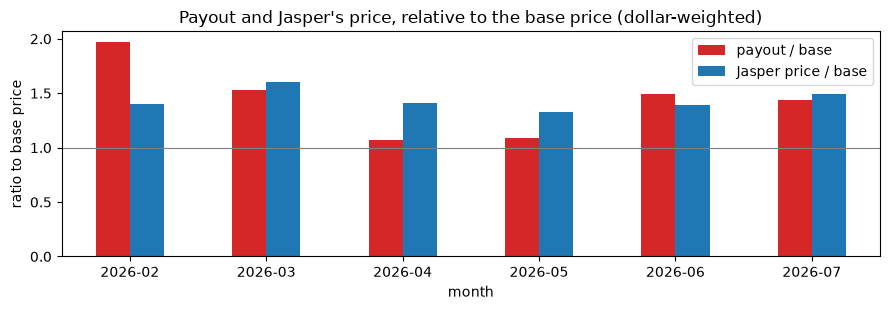

In [5]:
display(Markdown(f"""
## 2. What the data shows

- Training: 7,204 orders (February to July 2026). Validation: 4,155 orders (31 July to 14 October 2026).
- The payout rule was verified on the training orders: the payout matches (strike - price at close) x size for
  99% of orders. **65% of traders close before expiry**, and the payout uses the price at the close.
- Jasper's base price is missing for **53% of validation orders** (all of September and October). Approach 1
  alone cannot price these orders.
- Payouts were higher than the base price in most months (ratio below). The ratio moves a lot from month to month,
  because a few large orders make a large part of all payouts (in March, the 10 largest orders made 85% of payouts).
"""))
fig, ax = plt.subplots(figsize=(9, 3.2))
eda_m.set_index("month")[["payout / base", "Jasper price / base"]].plot.bar(ax=ax, rot=0, color=["#d62728", "#1f77b4"])
ax.axhline(1, color="grey", lw=0.8)
ax.set_title("Payout and Jasper's price, relative to the base price (dollar-weighted)")
ax.set_ylabel("ratio to base price"); plt.tight_layout(); plt.show()

In [6]:
display(Markdown("""
## 3. The model

| Part | What it does | Why |
|---|---|---|
| Fair value | Black-Scholes with a volatility forecast (HAR model, BTC 1-minute data) for the order's duration | Own model, works without Jasper's base price |
| Anchor | Jasper's base price; where missing, a model rebuilds it from the fair value and market features | Approach 1 where possible, approach 2 where not |
| Risk multiplier | Expected payout = anchor x calibration factor (x economic-calendar factor) | Learned from real payouts |
| Reference price | The price customers pay today, as a factor on the anchor (learned from Jasper's real prices) | Needed by the pricing rule |
| Pricing rule | **premium = expected payout + reference price / 3**, kept between 0.85 and 1.6 x the reference price, never below the expected payout | Highest expected profit under the demand assumption |

**Demand assumption (moderate).** Share of orders kept = exp(-3 x (our price / price paid - 1)), at most 1.5.
A price 10% above today's price keeps 74% of the orders; a price 10% lower brings 35% more orders.
Jasper Vault said it has no formula for this, so we also show results for no, low and high sensitivity.

**No leaks.** Every input is known when the order is created: market features use only finished BTC minutes before the
order; economic releases are scheduled in advance; the validation closing times are never used.
"""))


## 3. The model

| Part | What it does | Why |
|---|---|---|
| Fair value | Black-Scholes with a volatility forecast (HAR model, BTC 1-minute data) for the order's duration | Own model, works without Jasper's base price |
| Anchor | Jasper's base price; where missing, a model rebuilds it from the fair value and market features | Approach 1 where possible, approach 2 where not |
| Risk multiplier | Expected payout = anchor x calibration factor (x economic-calendar factor) | Learned from real payouts |
| Reference price | The price customers pay today, as a factor on the anchor (learned from Jasper's real prices) | Needed by the pricing rule |
| Pricing rule | **premium = expected payout + reference price / 3**, kept between 0.85 and 1.6 x the reference price, never below the expected payout | Highest expected profit under the demand assumption |

**Demand assumption (moderate).** Share of orders kept = exp(-3 x (our price / price paid - 1)), at most 1.5.
A price 10% above today's price keeps 74% of the orders; a price 10% lower brings 35% more orders.
Jasper Vault said it has no formula for this, so we also show results for no, low and high sensitivity.

**No leaks.** Every input is known when the order is created: market features use only finished BTC minutes before the
order; economic releases are scheduled in advance; the validation closing times are never used.


In [7]:
v = pd.read_csv(OUT / "validation_premiums.csv")
v["release_in_window"] = pd.read_parquet(OUT / "external_valid.parquet")["event_in_window"].to_numpy()
A, mu = v["anchor_per_BTC_USDC"], v["expected_payout_per_BTC_USDC"]
R, P = v["reference_price_per_BTC_USDC"], v["premium_per_BTC_USDC"]
v["risk_multiplier"], v["reference_factor"] = mu / A, R / A
v["raw"] = mu + R / val["k"]
v["cap_hit"] = np.where(v["raw"] > val["cap_hi"] * R + 1e-9, "upper cap", np.where(v["raw"] < val["cap_lo"] * R - 1e-9, "lower cap", "none"))
rm = v.groupby("release_in_window")["risk_multiplier"].agg(["mean", "min", "max"])
rf = v.groupby("productType")["reference_factor"].median()
display(Markdown(f"""
### 3.1 How one premium is calculated

The model sets a price **per 1 BTC** and then multiplies it by the order size. Five steps:

1. **Anchor.** Jasper's base price for the order. If the file has no base price (all of September and October, part of August),
   our model rebuilds it from the volatility forecast and recent market data.
2. **Expected payout = anchor x risk multiplier.** The risk multiplier corrects the base price, which is too low on average.
   It is **{rm.loc[0, 'mean']:.2f}** on average for normal orders ({rm.loc[0, 'min']:.2f} to {rm.loc[0, 'max']:.2f}) and
   **{rm.loc[1, 'mean']:.2f}** when a scheduled US release (CPI, jobs report, PPI, PCE, GDP, Fed decision) falls inside the
   protection window. The small changes inside each group come from the hours to the next and since the last release.
3. **Reference price = anchor x reference factor.** This is the price customers typically pay today for this kind of order,
   learned from Jasper's real prices (median factor: 30 min {rf.loc[1800]:.2f}, 1 h {rf.loc[3600]:.2f}, 2 h {rf.loc[7200]:.2f},
   4 h {rf.loc[14400]:.2f}, 8 h {rf.loc[28800]:.2f}, 12 h {rf.loc[43200]:.2f}, 24 h {rf.loc[86400]:.2f} x anchor).
4. **Premium = expected payout + reference price / {val['k']:g}.** Under the moderate demand assumption, this margin gives the
   highest expected profit: a larger margin loses too many customers, a smaller one gives up profit.
5. **Caps.** The premium must stay between {val['cap_lo']} and {val['cap_hi']} x the reference price, and never below the expected
   payout. In the validation file, {np.mean(v.cap_hit == "upper cap"):.1%} of orders hit the upper cap and
   {np.mean(v.cap_hit == "lower cap"):.1%} the lower cap.

**Outputs:** premium for the order = premium per BTC x size (`premiumAmount_USDC`), and
multiplier = premium per BTC / anchor (`pricingMultiplier`).
"""))


### 3.1 How one premium is calculated

The model sets a price **per 1 BTC** and then multiplies it by the order size. Five steps:

1. **Anchor.** Jasper's base price for the order. If the file has no base price (all of September and October, part of August),
   our model rebuilds it from the volatility forecast and recent market data.
2. **Expected payout = anchor x risk multiplier.** The risk multiplier corrects the base price, which is too low on average.
   It is **1.32** on average for normal orders (1.25 to 1.41) and
   **1.72** when a scheduled US release (CPI, jobs report, PPI, PCE, GDP, Fed decision) falls inside the
   protection window. The small changes inside each group come from the hours to the next and since the last release.
3. **Reference price = anchor x reference factor.** This is the price customers typically pay today for this kind of order,
   learned from Jasper's real prices (median factor: 30 min 1.93, 1 h 1.63, 2 h 1.40,
   4 h 1.31, 8 h 1.30, 12 h 1.36, 24 h 1.43 x anchor).
4. **Premium = expected payout + reference price / 3.** Under the moderate demand assumption, this margin gives the
   highest expected profit: a larger margin loses too many customers, a smaller one gives up profit.
5. **Caps.** The premium must stay between 0.85 and 1.6 x the reference price, and never below the expected
   payout. In the validation file, 2.4% of orders hit the upper cap and
   0.2% the lower cap.

**Outputs:** premium for the order = premium per BTC x size (`premiumAmount_USDC`), and
multiplier = premium per BTC / anchor (`pricingMultiplier`).


In [8]:
def example(row, label):
    return pd.Series({
        "Order": f"{row.optionType_label}, {row.productType / 3600:g} h, created {row.createdAt}",
        "Size (BTC)": f"{row.quantity_BTC:.4f}",
        "1. Anchor (USDC per BTC)": f"{row.anchor_per_BTC_USDC:,.2f}  ({'Jasper base price' if row.anchor_source == 'jasper' else 'rebuilt base price'})",
        "2. Risk multiplier": f"{row.risk_multiplier:.3f}  ({'release in window' if row.release_in_window else 'no release in window'})",
        "   Expected payout": f"{row.anchor_per_BTC_USDC:,.2f} x {row.risk_multiplier:.3f} = {row.expected_payout_per_BTC_USDC:,.2f}",
        "3. Reference price": f"{row.anchor_per_BTC_USDC:,.2f} x {row.reference_factor:.3f} = {row.reference_price_per_BTC_USDC:,.2f}",
        "4. Raw premium": f"{row.expected_payout_per_BTC_USDC:,.2f} + {row.reference_price_per_BTC_USDC:,.2f} / {val['k']:g} = {row.raw:,.2f}",
        "5. Allowed range": f"{val['cap_lo'] * row.reference_price_per_BTC_USDC:,.2f} to {val['cap_hi'] * row.reference_price_per_BTC_USDC:,.2f}  (cap hit: {row.cap_hit})",
        "Premium per BTC": f"{row.premium_per_BTC_USDC:,.2f}",
        "Premium for the order (USDC)": f"{row.premium_per_BTC_USDC:,.2f} x {row.quantity_BTC:.4f} = {row.premiumAmount_USDC:,.4f}",
        "Multiplier": f"{row.premium_per_BTC_USDC:,.2f} / {row.anchor_per_BTC_USDC:,.2f} = {row.pricingMultiplier:.3f}",
    }, name=label)
ex_a = v[(v.anchor_source == "jasper") & (v.release_in_window == 0) & (v.cap_hit == "none")].iloc[0]
pool_b = v[(v.release_in_window == 1) & (v.cap_hit == "upper cap")]
ex_b = (pool_b if len(pool_b) else v[v.release_in_window == 1]).iloc[0]
display(Markdown("### 3.2 Two worked examples from the validation file"))
display(pd.concat([example(ex_a, "Example A: normal order"), example(ex_b, "Example B: release in window")], axis=1))

### 3.2 Two worked examples from the validation file

,Example A: normal order,Example B: release in window
Order,"Put, 1 h, created 2026/7/31 17:11","Put, 8 h, created 2026/8/7 7:42"
Size (BTC),0.0023,0.0777
1. Anchor (USDC per BTC),67.94 (Jasper base price),201.91 (Jasper base price)
2. Risk multiplier,1.261 (no release in window),1.731 (release in window)
Expected payout,67.94 x 1.261 = 85.70,201.91 x 1.731 = 349.47
3. Reference price,67.94 x 1.899 = 129.04,201.91 x 1.307 = 263.99
4. Raw premium,85.70 + 129.04 / 3 = 128.72,349.47 + 263.99 / 3 = 437.47
5. Allowed range,109.68 to 206.46 (cap hit: none),224.39 to 422.38 (cap hit: upper cap)
Premium per BTC,128.72,422.38
Premium for the order (USDC),128.72 x 0.0023 = 0.3024,422.38 x 0.0777 = 32.8397


In [9]:
display(Markdown("""
## 4. Backtest: May, June and July

Each test month uses a model fitted only on the earlier months. Profit is in USDC, summed over the three months.
"""))
show = bt.copy()
show["method"] = show["method"].map(nice)
cols = {"method": "Method", "profit_moderate": "Profit, moderate", "profit_none": "Profit, no sensitivity",
        "profit_low": "Profit, low", "profit_high": "Profit, high", "share_below_paid": "Orders cheaper than today",
        "share_above_1.5x_paid": "Orders above 1.5x today"}
t = show[list(cols)].rename(columns=cols).set_index("Method")
display(t.style.format({c: "{:,.0f}" for c in t.columns[:4]} | {c: "{:.0%}" for c in t.columns[4:]}))


## 4. Backtest: May, June and July

Each test month uses a model fitted only on the earlier months. Profit is in USDC, summed over the three months.


,"Profit, moderate","Profit, no sensitivity","Profit, low","Profit, high",Orders cheaper than today,Orders above 1.5x today
Method,,,,,,
base price x best constant,"38,383","84,662","53,044","25,836",25%,25%
"Hybrid + calendar, simple reference price","34,649","65,206","44,461","26,171",30%,18%
Hybrid + economic calendar,"34,124","51,556","39,909","28,214",30%,13%
Hybrid + calendar + Fear & Greed,"33,813","55,217","40,537","27,542",32%,13%
"Hybrid, constant multiplier","32,815","47,775","38,671","25,842",31%,8%
Hybrid + Fear & Greed,"32,415","49,859","38,755","25,807",34%,11%
Hybrid + market inputs,"32,310","50,521","39,161","25,586",30%,9%
Hybrid + order size (capped),"31,488","47,194","37,658","24,183",40%,6%
Hybrid + all inputs (boosting),"28,981","55,603","38,236","21,089",30%,12%


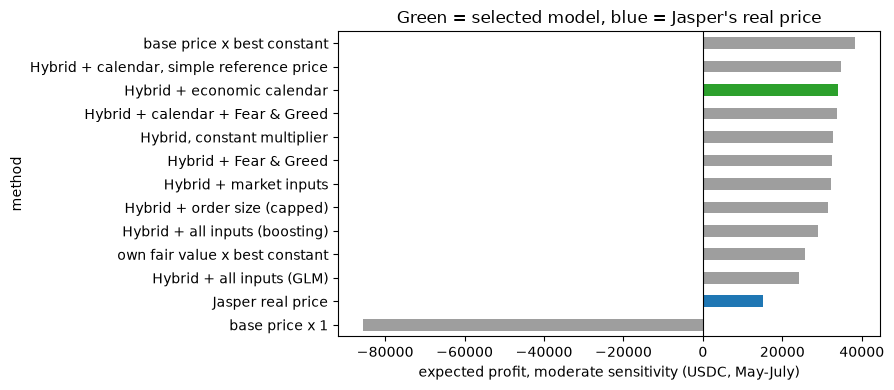

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
p = show.set_index("method")["profit_moderate"].sort_values()
colors = ["#2ca02c" if m == nice(S) else ("#1f77b4" if m == "Jasper real price" else "#9e9e9e") for m in p.index]
p.plot.barh(ax=ax, color=colors); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("expected profit, moderate sensitivity (USDC, May-July)"); ax.set_title("Green = selected model, blue = Jasper's real price")
plt.tight_layout(); plt.show()


**Why not "base price x best constant"?** It earns 38,383 USDC under moderate sensitivity, but it is
mostly a general price increase: its median price is 1.29 x today's price, and it puts
**25%** of orders above 1.5 x today's price (selected model: 13%).
The brief says that simply increasing every price is not a valid solution, and its advantage disappears when customers
are more price-sensitive (high sensitivity: 25,836 vs 28,214 USDC for the selected model).


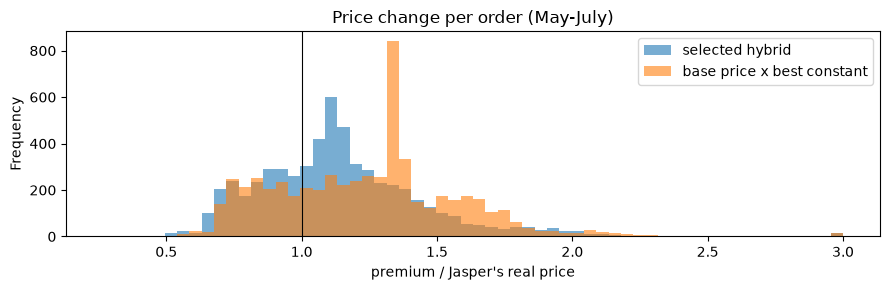

In [11]:
display(Markdown(f"""
**Why not "base price x best constant"?** It earns {raise_all.profit_moderate:,.0f} USDC under moderate sensitivity, but it is
mostly a general price increase: its median price is {raise_all.median_price_vs_paid:.2f} x today's price, and it puts
**{raise_all['share_above_1.5x_paid']:.0%}** of orders above 1.5 x today's price (selected model: {best['share_above_1.5x_paid']:.0%}).
The brief says that simply increasing every price is not a valid solution, and its advantage disappears when customers
are more price-sensitive (high sensitivity: {raise_all.profit_high:,.0f} vs {best.profit_high:,.0f} USDC for the selected model).
"""))
fig, ax = plt.subplots(figsize=(9, 3))
pr.clip(0, 3).plot.hist(bins=60, alpha=0.6, ax=ax)
ax.axvline(1, color="black", lw=0.8); ax.set_xlabel("premium / Jasper's real price"); ax.set_title("Price change per order (May-July)")
plt.tight_layout(); plt.show()

In [12]:
display(Markdown("### Gain against Jasper's real price (90% confidence interval, whole days resampled)"))
c = ci.copy(); c["method"] = c["method"].map(lambda m: "Selected: " + nice(m[len("selected: "):]) if m.startswith("selected: ") else nice(m))
display(c.pivot(index="method", columns="demand", values="gain")[["none", "low", "moderate", "high"]].style.format("{:,.0f}"))
cm = c[c.demand == "moderate"][["method", "gain", "ci_low", "ci_high", "P(gain > 0)"]]
display(cm.style.format({"gain": "{:,.0f}", "ci_low": "{:,.0f}", "ci_high": "{:,.0f}", "P(gain > 0)": "{:.0%}"}).hide(axis="index"))

### Gain against Jasper's real price (90% confidence interval, whole days resampled)

demand,none,low,moderate,high
method,,,,
"Hybrid, constant multiplier","32,580","23,475","17,620","10,647"
Selected: Hybrid + economic calendar,"36,361","24,714","18,928","13,019"
base price x best constant,"69,467","37,849","23,188","10,640"


method,gain,ci_low,ci_high,P(gain > 0)
Selected: Hybrid + economic calendar,"18,928","6,482","33,832",100%
"Hybrid, constant multiplier","17,620","5,895","30,998",100%
base price x best constant,"23,188","6,000","43,538",99%


In [13]:
display(Markdown(f"""
## 5. Which inputs help? (tested, and mostly rejected)

A feature block is kept only if it improves both the prediction error and the moderate profit, pooled and in at least
2 of the 3 months. Result: **{nice(S)}** is selected.
"""))
ch = choice.copy(); ch["setup"] = ch["setup"].map(nice)
display(ch.style.format({"profit_moderate": "{:,.0f}"}).hide(axis="index"))
display(Markdown(f"""
- **Economic calendar:** payouts were {eda_e.iloc[1]['payout / base']:.2f} x the base price when a release fell inside the
  window ({int(eda_e.iloc[1]['orders'])} orders), against {eda_e.iloc[0]['payout / base']:.2f} x otherwise.
- **Order size:** it looked like the strongest signal inside the training months, but on new months the effect was small and
  changed direction. It did not pass the test, so the final model does not price by size.
- **Fear & Greed index:** did not pass.
- **News tone (GDELT):** {"used in the test" if ext.get("news_available") else "not tested: the GDELT service refused all requests from our connection (rate limit). This is a data limit, not a negative result."}
"""))


## 5. Which inputs help? (tested, and mostly rejected)

A feature block is kept only if it improves both the prediction error and the moderate profit, pooled and in at least
2 of the 3 months. Result: **Hybrid + economic calendar** is selected.


setup,deviance better (months),profit better (months),deviance better (pooled),profit better (pooled),passes,profit_moderate
Hybrid + economic calendar,2,3,True,True,True,"34,124"
Hybrid + calendar + Fear & Greed,1,2,False,True,False,"33,813"
Hybrid + Fear & Greed,1,1,False,False,False,"32,415"
Hybrid + market inputs,0,1,False,False,False,"32,310"
Hybrid + order size (capped),2,2,False,False,False,"31,488"
Hybrid + all inputs (boosting),1,0,False,False,False,"28,981"
Hybrid + all inputs (GLM),1,1,False,False,False,"24,111"



- **Economic calendar:** payouts were 1.82 x the base price when a release fell inside the
  window (317 orders), against 1.35 x otherwise.
- **Order size:** it looked like the strongest signal inside the training months, but on new months the effect was small and
  changed direction. It did not pass the test, so the final model does not price by size.
- **Fear & Greed index:** did not pass.
- **News tone (GDELT):** not tested: the GDELT service refused all requests from our connection (rate limit). This is a data limit, not a negative result.


In [14]:
display(Markdown("## 6. Segments: selected model against Jasper's real price (moderate sensitivity, May-July)"))
s = seg.copy()
display(s.style.format({"jasper_profit": "{:,.0f}", "our_profit": "{:,.0f}", "median_price_ratio": "{:.2f}"}).hide(axis="index"))

## 6. Segments: selected model against Jasper's real price (moderate sensitivity, May-July)

group,segment,orders,jasper_profit,our_profit,median_price_ratio
0.5 h,duration,2116,"16,176","12,971",0.91
1 h,duration,531,"1,395","4,432",1.08
12 h,duration,46,51,57,1.12
2 h,duration,1021,"5,943","9,047",1.17
24 h,duration,117,845,735,1.13
4 h,duration,1096,"-9,186",642,1.21
8 h,duration,879,-29,"6,239",1.22
Call,type,3169,"20,036","28,977",1.10
Put,type,2637,"-4,841","5,146",1.12
smallest 20%,size_group,1162,228,183,1.05


In [15]:
display(Markdown(f"""
## 7. Validation premiums

- File: `outputs/validation_premiums.csv`, {val['orders']:,} rows in the input order. **Decision: we give both outputs** for
  every order: `premiumAmount_USDC` (premium in USDC) and `pricingMultiplier` (premium / anchor). The brief accepts either,
  and both make the file easy to compare with other approaches. Extra columns: premium per BTC, anchor and its source,
  expected payout and reference price.
- Total premium: **{val['premium_total_usd']:,.0f} USDC**; total expected payout by our model: **{val['expected_payout_total_usd']:,.0f} USDC**.
- September and October depend fully on the rebuilt base price. Checked on August orders (with a model that did not see any
  validation base price), the rebuild error was **{val['rebuild_error_august']['median_abs_error']:.0%}** (median) and the
  average bias **{val['rebuild_error_august']['mean_error']:+.0%}** (the rebuilt price was too high). The final model also
  learns from the August base prices, which should reduce this bias; for September and October it cannot be measured.
- For the {val['known_price_rows']} validation orders where the file gives Jasper's real price, our premium is
  {val['known_price_median_ratio']:.2f} x Jasper's price (median); lower for {val['known_price_share_lower']:.0%}, above 1.5 x for {val['known_price_share_above_1.5']:.0%}.
"""))
bm = by_month.set_index("month")
display(bm.style.format({"rebuilt_anchor_share": "{:.0%}", "median_premium_per_BTC": "{:,.1f}", "median_anchor_per_BTC": "{:,.1f}",
                         "premium_total_usd": "{:,.0f}", "expected_payout_usd": "{:,.0f}"}))


## 7. Validation premiums

- File: `outputs/validation_premiums.csv`, 4,155 rows in the input order. **Decision: we give both outputs** for
  every order: `premiumAmount_USDC` (premium in USDC) and `pricingMultiplier` (premium / anchor). The brief accepts either,
  and both make the file easy to compare with other approaches. Extra columns: premium per BTC, anchor and its source,
  expected payout and reference price.
- Total premium: **216,764 USDC**; total expected payout by our model: **160,251 USDC**.
- September and October depend fully on the rebuilt base price. Checked on August orders (with a model that did not see any
  validation base price), the rebuild error was **9%** (median) and the
  average bias **+9%** (the rebuilt price was too high). The final model also
  learns from the August base prices, which should reduce this bias; for September and October it cannot be measured.
- For the 544 validation orders where the file gives Jasper's real price, our premium is
  1.19 x Jasper's price (median); lower for 30%, above 1.5 x for 4%.


,orders,rebuilt_anchor_share,median_premium_per_BTC,median_anchor_per_BTC,premium_total_usd,expected_payout_usd
month,,,,,,
2026-07,118,0%,93.9,48.2,70,47
2026-08,2129,13%,189.0,99.2,"98,144","73,828"
2026-09,1340,100%,225.4,118.6,"87,631","64,242"
2026-10,568,100%,213.1,110.0,"30,918","22,135"


In [16]:
half = seg[(seg.segment == "duration") & (seg.group == "0.5 h")].iloc[0]
display(Markdown(f"""
## 8. Limits and assumptions

Some facts were not available from Jasper Vault before the submission. For each one we state the assumption we made
and its effect.

**Unknown information**

- **The scoring rule for price sensitivity is unknown.** The brief says Jasper Vault will apply a "simplified pricing /
  conversion constraint", but it does not give the formula, and Jasper Vault said in the meeting that it cannot measure this
  relation. *Assumption:* moderate sensitivity (k = 3). *Effect:* the gain against Jasper's price is clear for no, low and
  moderate sensitivity; under high sensitivity the 90% confidence interval includes zero. If the real rule punishes price
  increases more strongly, our profit gain becomes smaller.
- **The reason for the missing base prices is unknown.** The base price is missing for some training orders and for all
  validation orders after August. *Assumption:* the missing base prices follow the same pattern as the known ones, so a model
  can rebuild them. *Effect:* in a check on August, the rebuilt price had a median error of {val['rebuild_error_august']['median_abs_error']:.0%}
  and was {val['rebuild_error_august']['mean_error']:+.0%} too high on average. This error adds to the pricing error in September and October.
- **The meaning of the strike is not confirmed.** For 37% of training orders the strike has many decimals and is probably the
  entry price of the trader's position, not the market price at purchase. *Assumption:* we use the strike as given. *Effect:* the
  final premium does not depend on the distance between the strike and the market price, because that input did not improve
  the test results on new months. Orders far from the money (about 12% in training) can be priced too high.

**Model limits**

- **30-minute orders.** For these, our premium is lower than Jasper's price (median {half.median_price_ratio:.2f} x), and the expected
  profit is lower ({half.our_profit:,.0f} vs {half.jasper_profit:,.0f} USDC). Jasper's markup on 30-minute orders already works;
  a separate rule for this duration is a possible next step.
- **Few large orders drive the results.** Profit totals move a lot when a few large orders pay out. The confidence intervals
  show this; three test months is a short period.
- **No news sentiment.** The free news source (GDELT) refused our requests, and CoinDesk news needs a paid key.
- **Validation closing times are present in the file.** We do not use them, because they are not known when the premium is set.
"""))


## 8. Limits and assumptions

Some facts were not available from Jasper Vault before the submission. For each one we state the assumption we made
and its effect.

**Unknown information**

- **The scoring rule for price sensitivity is unknown.** The brief says Jasper Vault will apply a "simplified pricing /
  conversion constraint", but it does not give the formula, and Jasper Vault said in the meeting that it cannot measure this
  relation. *Assumption:* moderate sensitivity (k = 3). *Effect:* the gain against Jasper's price is clear for no, low and
  moderate sensitivity; under high sensitivity the 90% confidence interval includes zero. If the real rule punishes price
  increases more strongly, our profit gain becomes smaller.
- **The reason for the missing base prices is unknown.** The base price is missing for some training orders and for all
  validation orders after August. *Assumption:* the missing base prices follow the same pattern as the known ones, so a model
  can rebuild them. *Effect:* in a check on August, the rebuilt price had a median error of 9%
  and was +9% too high on average. This error adds to the pricing error in September and October.
- **The meaning of the strike is not confirmed.** For 37% of training orders the strike has many decimals and is probably the
  entry price of the trader's position, not the market price at purchase. *Assumption:* we use the strike as given. *Effect:* the
  final premium does not depend on the distance between the strike and the market price, because that input did not improve
  the test results on new months. Orders far from the money (about 12% in training) can be priced too high.

**Model limits**

- **30-minute orders.** For these, our premium is lower than Jasper's price (median 0.91 x), and the expected
  profit is lower (12,971 vs 16,176 USDC). Jasper's markup on 30-minute orders already works;
  a separate rule for this duration is a possible next step.
- **Few large orders drive the results.** Profit totals move a lot when a few large orders pay out. The confidence intervals
  show this; three test months is a short period.
- **No news sentiment.** The free news source (GDELT) refused our requests, and CoinDesk news needs a paid key.
- **Validation closing times are present in the file.** We do not use them, because they are not known when the premium is set.
